In [4]:
# Instalamos gdown, la herramienta que descarga archivos de Google Drive usando su ID
!pip install gdown --quiet

import gdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Semilla fija: cualquier muestreo aleatorio dará el mismo resultado cada vez que se ejecute
np.random.seed(42)

# IDs de los dos archivos de la ENIGH 2024 en Google Drive
id_gastoshogar = "1g7nIJaiyyVsSTAO561X5KtSw_K1GZuA0"
id_concentradohogar = "1BfNgZ8cGUoYdbJryD45P8uklzA6zDLCA"

# Descargamos los archivos a la carpeta de trabajo de Colab
gdown.download(id=id_gastoshogar, output="2024gastoshogar.csv", quiet=True)
gdown.download(id=id_concentradohogar, output="2024concentradohogar.csv", quiet=True)

# Leemos los archivos; 'clave' se lee como texto para no perder ceros iniciales ni letras (ej. 01113A)
df_gastos = pd.read_csv("2024gastoshogar.csv", dtype={'clave': str})
df_concentrado = pd.read_csv("2024concentradohogar.csv")

print("Gastos:", df_gastos.shape)
print("Concentrado:", df_concentrado.shape)

# Revisamos que existan las columnas que vamos a necesitar del concentrado
columnas_deseadas = ['folioviv', 'foliohog', 'ing_cor', 'tam_loc', 'est_socio',
                     'factor', 'sexo_jefe', 'tot_integ']
print("\nColumnas disponibles en el concentrado:")
print({col: (col in df_concentrado.columns) for col in columnas_deseadas})

# Columnas del archivo de gastos
print("\nColumnas de gastos:", df_gastos.columns.tolist())

# Convertimos gasto_tri a número (viene como texto); lo que no se pueda convertir queda vacío
df_gastos['gasto_tri'] = pd.to_numeric(df_gastos['gasto_tri'], errors='coerce')

# Primeros 3 dígitos de la clave: indican el tipo de gasto (011 = alimentos, 012 = bebidas no alcohólicas)
df_gastos['grupo3'] = df_gastos['clave'].str[:3]

print("\nPrimeros 3 dígitos de clave (los 15 más frecuentes):")
print(df_gastos['grupo3'].value_counts().head(15))

# Cuántos registros y cuánto gasto hay en alimentos (011) y en bebidas no alcohólicas (012)
print("\nRegistros y gasto total en 011 y 012:")
print(df_gastos[df_gastos['grupo3'].isin(['011', '012'])]
      .groupby('grupo3')['gasto_tri'].agg(['count', 'sum']).round(0))

# Claves cuya clasificación queremos revisar: galletas, pan dulce, yogur, bebidas lácteas, hierbas
claves_a_revisar = ['011135', '011136', '011137', '011138', '011460', '011471',
                    '011942', '011943', '011944', '011945', '011946']
print("\nRegistros y gasto de las claves a revisar:")
print(df_gastos[df_gastos['clave'].isin(claves_a_revisar)]
      .groupby('clave')['gasto_tri'].agg(['count', 'sum']).round(0))

Gastos: (5311497, 31)
Concentrado: (91414, 126)

Columnas disponibles en el concentrado:
{'folioviv': True, 'foliohog': True, 'ing_cor': True, 'tam_loc': True, 'est_socio': True, 'factor': True, 'sexo_jefe': True, 'tot_integ': True}

Columnas de gastos: ['folioviv', 'foliohog', 'clave', 'tipo_gasto', 'mes_dia', 'forma_pag1', 'forma_pag2', 'forma_pag3', 'lugar_comp', 'orga_inst', 'frecuencia', 'fecha_adqu', 'fecha_pago', 'cantidad', 'gasto', 'pago_mp', 'costo', 'inmujer', 'inst_1', 'inst_2', 'num_meses', 'num_pagos', 'ultim_pago', 'gasto_tri', 'gasto_nm', 'gas_nm_tri', 'imujer_tri', 'entidad', 'est_dis', 'upm', 'factor']

Primeros 3 dígitos de clave (los 15 más frecuentes):
grupo3
011    1741147
131     660889
056     596833
111     314997
031     257976
012     253317
083     172242
045     142117
181     131000
061     130807
072     102192
032      96287
046      90324
044      82286
097      59166
Name: count, dtype: int64

Registros y gasto total en 011 y 012:
          count      

In [5]:
# Claves procesadas, según el catálogo de gastos de la ENIGH 2024 (INEGI)
procesados = {
    # Cereales y derivados
    '011134', '011135', '011136', '011137', '011138', '011139', '01113A', '011140', '011150',
    '011191', '011192', '011195', '011196',
    # Carnes: embutidos, ahumados y preparados
    '011231', '011232', '011233', '011234', '011235',
    '011251', '011252', '011253', '011254', '011255', '011256',
    # Pescados y mariscos: secos, enlatados, empanizados y preparados
    '011321', '011322', '011323', '011324', '011331', '011332',
    '011351', '011352', '011360',
    # Lácteos
    '011432', '011441', '011442', '011452', '011460', '011471', '011472', '011473', '011490',
    # Grasas y frutas
    '011530', '011592', '011691', '011692',
    # Hortalizas y legumbres procesadas
    '011791', '011794', '011795', '011796', '011797', '011798', '011799', '01179A',
    # Azúcar, confitería y postres
    '011833', '011834', '011841', '011842', '011843', '011851', '011852', '011853',
    '011861', '011891', '011892', '011893',
    # Alimentos preparados y otros
    '011911', '011912', '011921', '011922', '011923', '011924', '011925',
    '011931', '011932', '011933', '011934', '011935', '011938',
    '011991', '011992', '011993', '011994', '011995', '011996',
    # Bebidas no alcohólicas procesadas
    '012100', '012201', '012203', '012400', '012601', '012602', '012603', '012604',
    '012901', '012902', '012903', '012904', '012905', '012907',
}

# Ingredientes culinarios: se reportan aparte
ingredientes = {'011511', '011512', '011520', '011591', '011593',
                '011810', '011820', '011831', '011832', '011936', '011937'}

# Agua e hielo: no se analizan
agua = {'011862', '012501', '012502'}

# Bebidas 012 que sí cuentan como frescas (café en grano o molido, té en bolsa y en hojas)
frescos_012 = {'012202', '012301', '012302'}

def clasificar_clave(clave):
    clave = str(clave).strip()
    # Lo que no empieza con 011 o 012 no es alimento ni bebida no alcohólica
    if clave[:3] not in ('011', '012'):
        return 'Otro'
    if clave in agua:
        return 'Agua'
    if clave in ingredientes:
        return 'Ingrediente'
    if clave in procesados:
        return 'Procesado'
    # Una clave 012 que no está en ninguna lista queda marcada para revisarla
    if clave[:3] == '012' and clave not in frescos_012:
        return 'Revisar'
    # Todo lo demás de la sección 011 es fresco o mínimamente procesado
    return 'Fresco'

# Clasificamos solo las claves únicas (más rápido) y luego asignamos a cada registro
mapa_categoria = {c: clasificar_clave(c) for c in df_gastos['clave'].dropna().unique()}
df_gastos['categoria'] = df_gastos['clave'].map(mapa_categoria)
df_gastos['grupo4'] = df_gastos['clave'].str[:4]

# Registros y gasto por categoría, con su porcentaje del gasto en alimentos y bebidas
resumen = df_gastos.dropna(subset=['gasto_tri']).groupby('categoria')['gasto_tri'].agg(['count', 'sum']).round(0)
alimentos = resumen.drop(index='Otro', errors='ignore').copy()
alimentos['porcentaje'] = (alimentos['sum'] / alimentos['sum'].sum() * 100).round(1)
print(alimentos)

# Claves 012 que no están en ninguna lista (deberían ser cero)
print("\nClaves por revisar:", sorted(df_gastos.loc[df_gastos['categoria'] == 'Revisar', 'clave'].unique()))

# Gasto por grupo de 4 dígitos y categoría, para auditar la clasificación
auditoria = df_gastos[df_gastos['categoria'].isin(['Fresco', 'Procesado', 'Ingrediente', 'Agua'])]
print("\nGasto por grupo y categoría:")
print(auditoria.pivot_table(index='grupo4', columns='categoria', values='gasto_tri',
                            aggfunc='sum', fill_value=0).round(0))

# Las 25 claves con más gasto en frescos y en procesados, para revisar que tengan sentido
for cat in ['Fresco', 'Procesado']:
    print(f"\nClaves con más gasto en {cat}:")
    print(df_gastos[df_gastos['categoria'] == cat].groupby('clave')['gasto_tri']
          .sum().sort_values(ascending=False).head(25).round(0))

               count          sum  porcentaje
categoria                                    
Agua           41236   19646197.0         2.1
Fresco       1253102  604938596.0        65.0
Ingrediente    61676   31193992.0         3.4
Procesado     541978  275196644.0        29.6

Claves por revisar: []

Gasto por grupo y categoría:
categoria        Agua       Fresco  Ingrediente   Procesado
grupo4                                                     
0111              0.0  130643600.0          0.0  68540344.0
0112              0.0  141126842.0          0.0  32451160.0
0113              0.0   13857844.0          0.0   8168818.0
0114              0.0  133236211.0          0.0  12056393.0
0115              0.0          0.0   18163762.0   7950858.0
0116              0.0   55075460.0          0.0    243008.0
0117              0.0  125806944.0          0.0  13602757.0
0118         460648.0          0.0   11682417.0   6971738.0
0119              0.0    1921677.0    1347814.0  38381166.0
0121      

In [6]:
llave = ['folioviv', 'foliohog']

# Nos quedamos con fresco, procesado e ingredientes, y solo con gasto válido
gastos_analisis = df_gastos[df_gastos['categoria'].isin(['Fresco', 'Procesado', 'Ingrediente'])].dropna(subset=['gasto_tri']).copy()

# Gasto por hogar y categoría (una columna por categoría)
por_categoria = gastos_analisis.pivot_table(index=llave, columns='categoria', values='gasto_tri',
                                            aggfunc='sum', fill_value=0).reset_index()
por_categoria.columns.name = None
por_categoria = por_categoria.rename(columns={'Fresco': 'gasto_fresco', 'Procesado': 'gasto_procesado',
                                              'Ingrediente': 'gasto_ingrediente'})

# Gasto por hogar y grupo de 4 dígitos (cereales, carnes, etc.); lo usaremos para PCA y UMAP
por_grupo = gastos_analisis.pivot_table(index=llave, columns='grupo4', values='gasto_tri',
                                        aggfunc='sum', fill_value=0)
por_grupo.columns = ['g_' + c for c in por_grupo.columns]
por_grupo = por_grupo.reset_index()

# Entidad federativa de cada hogar (viene del archivo de gastos)
entidad_hogar = df_gastos.groupby(llave)['entidad'].first().reset_index()

hogares = por_categoria.merge(por_grupo, on=llave).merge(entidad_hogar, on=llave)

# gasto_base = fresco + procesado; con él se calcula la proporción (los ingredientes quedan aparte)
hogares['gasto_base'] = hogares['gasto_fresco'] + hogares['gasto_procesado']
hogares['gasto_total_alim'] = hogares['gasto_base'] + hogares['gasto_ingrediente']
hogares = hogares[hogares['gasto_base'] > 0].copy()
hogares['prop_fresco'] = hogares['gasto_fresco'] / hogares['gasto_base']

# Unimos con las variables del concentrado
cols_conc = ['folioviv', 'foliohog', 'ing_cor', 'tam_loc', 'est_socio', 'factor', 'sexo_jefe', 'tot_integ']
df = hogares.merge(df_concentrado[cols_conc], on=llave, how='inner')

# Embudo de filtrado de hogares
print("Hogares en el concentrado:", len(df_concentrado))
print("Hogares con gasto en fresco o procesado:", len(hogares))
print("Hogares en el dataset final:", len(df))

# Perfil de los hogares excluidos frente a los incluidos (estrato socioeconómico)
excluidos = df_concentrado[~df_concentrado.set_index(llave).index.isin(df.set_index(llave).index)]
print("\nHogares excluidos:", len(excluidos))
print("Estrato en excluidos:\n", excluidos['est_socio'].value_counts(normalize=True).sort_index().round(3))
print("Estrato en incluidos:\n", df['est_socio'].value_counts(normalize=True).sort_index().round(3))

# Dos formas de medir el porcentaje de frescos, sin ponderar y ponderado con el factor de expansión
w = df['factor']
print("\nPromedio por hogar, sin ponderar:", round(df['prop_fresco'].mean(), 4))
print("Promedio por hogar, ponderado:", round(np.average(df['prop_fresco'], weights=w), 4))
print("Razón de totales, sin ponderar:", round(df['gasto_fresco'].sum() / df['gasto_base'].sum(), 4))
print("Razón de totales, ponderada:", round((df['gasto_fresco'] * w).sum() / (df['gasto_base'] * w).sum(), 4))

# Por tamaño de localidad (1 = 100,000 o más habitantes; 4 = menos de 2,500) y por estrato
for var in ['tam_loc', 'est_socio']:
    print(f"\nPor {var}:")
    for nivel, g in df.groupby(var):
        print(nivel, "| hogares:", len(g),
              "| promedio:", round(g['prop_fresco'].mean(), 3),
              "| ponderado:", round(np.average(g['prop_fresco'], weights=g['factor']), 3),
              "| razón de totales:", round(g['gasto_fresco'].sum() / g['gasto_base'].sum(), 3))

print("\nTabla final:", df.shape)

Hogares en el concentrado: 91414
Hogares con gasto en fresco o procesado: 90122
Hogares en el dataset final: 90122

Hogares excluidos: 1292
Estrato en excluidos:
 est_socio
1    0.233
2    0.455
3    0.181
4    0.131
Name: proportion, dtype: float64
Estrato en incluidos:
 est_socio
1    0.207
2    0.508
3    0.196
4    0.089
Name: proportion, dtype: float64

Promedio por hogar, sin ponderar: 0.6792
Promedio por hogar, ponderado: 0.6848
Razón de totales, sin ponderar: 0.6873
Razón de totales, ponderada: 0.6905

Por tam_loc:
1 | hogares: 33815 | promedio: 0.645 | ponderado: 0.658 | razón de totales: 0.658
2 | hogares: 10336 | promedio: 0.685 | ponderado: 0.692 | razón de totales: 0.693
3 | hogares: 10737 | promedio: 0.713 | ponderado: 0.711 | razón de totales: 0.718
4 | hogares: 35234 | promedio: 0.699 | ponderado: 0.726 | razón de totales: 0.706

Por est_socio:
1 | hogares: 18633 | promedio: 0.706 | ponderado: 0.73 | razón de totales: 0.718
2 | hogares: 45796 | promedio: 0.685 | pondera

In [7]:
llave = ['folioviv', 'foliohog']

# Conjuntos de claves que vamos a mover en cada variante
pan_pasta = ['011134', '011135', '011136', '011137', '011138', '011139', '01113A', '011140', '011150']
lacteos_proc = ['011432', '011441', '011442', '011452', '011460', '011471', '011472', '011473', '011490']

# Registros con gasto válido y su factor de expansión
g = df_gastos[['folioviv', 'foliohog', 'clave', 'gasto_tri']].dropna(subset=['gasto_tri'])
g = g.merge(df_concentrado[llave + ['factor']], on=llave, how='inner')
g['gasto_pond'] = g['gasto_tri'] * g['factor']   # gasto ponderado por el factor de expansión

def pct_fresco(mapa, solo_011=False, ingredientes_como_fresco=False):
    """% de gasto fresco (razón de totales, ponderada) para una clasificación dada."""
    d = g.copy()
    d['cat'] = d['clave'].map(mapa)
    if ingredientes_como_fresco:
        d.loc[d['cat'] == 'Ingrediente', 'cat'] = 'Fresco'   # los ingredientes pasan a contar como fresco
    if solo_011:
        d = d[d['clave'].str[:3] == '011']                   # descartamos las bebidas 012
    d = d[d['cat'].isin(['Fresco', 'Procesado'])]
    tot = d.groupby('cat')['gasto_pond'].sum()
    return tot['Fresco'] / tot.sum()

def variante(cambios):
    """Copia la clasificación base y mueve las claves indicadas a otra categoría."""
    m = dict(mapa_categoria)
    for clave, nueva in cambios.items():
        if clave in m:
            m[clave] = nueva
    return m

resultados = {
    'Base (la que usamos)':                       pct_fresco(mapa_categoria),
    'Sin bebidas 012 (solo 011)':                 pct_fresco(mapa_categoria, solo_011=True),
    'Pan, galletas y pasta como Fresco':          pct_fresco(variante({c: 'Fresco' for c in pan_pasta})),
    'Lácteos procesados (yogur etc.) como Fresco': pct_fresco(variante({c: 'Fresco' for c in lacteos_proc})),
    'Leche 011411 como Procesado':                pct_fresco(variante({'011411': 'Procesado'})),
    'Ingredientes contados como Fresco':          pct_fresco(mapa_categoria, ingredientes_como_fresco=True),
    'Definición más laxa (011 + pan + lácteos)':  pct_fresco(variante({c: 'Fresco' for c in pan_pasta + lacteos_proc}), solo_011=True),
}
print("% de gasto en fresco (razón de totales ponderada)")
for nombre, valor in resultados.items():
    print(f"{nombre:<46} {valor:.3f}")

# Correlación entre ingreso y proporción de fresco (Spearman, porque el ingreso es muy asimétrico)
print("\nCorrelación Spearman prop_fresco vs ing_cor:",
      round(df['prop_fresco'].corr(df['ing_cor'], method='spearman'), 3))
print("Correlación Spearman prop_fresco vs tot_integ:",
      round(df['prop_fresco'].corr(df['tot_integ'], method='spearman'), 3))

# Guardamos la tabla por hogar como respaldo (se descarga a tu computadora)
df.to_csv('hogares_analisis.csv', index=False)
from google.colab import files
files.download('hogares_analisis.csv')

% de gasto en fresco (razón de totales ponderada)
Base (la que usamos)                           0.690
Sin bebidas 012 (solo 011)                     0.754
Pan, galletas y pasta como Fresco              0.763
Lácteos procesados (yogur etc.) como Fresco    0.705
Leche 011411 como Procesado                    0.646
Ingredientes contados como Fresco              0.700
Definición más laxa (011 + pan + lácteos)      0.849

Correlación Spearman prop_fresco vs ing_cor: -0.102
Correlación Spearman prop_fresco vs tot_integ: 0.044


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Media (sin ponderar)           0.6792
Media (ponderada)              0.6848
Mediana (sin ponderar)         0.7104
Mediana (ponderada)            0.7159
Media recortada 10%            0.6975
Desviación estándar            0.2131
MAD (desv. absoluta mediana)   0.1341

IC 95% bootstrap de la media ponderada: [0.6829, 0.6868]
Error estándar (bootstrap): 0.00097


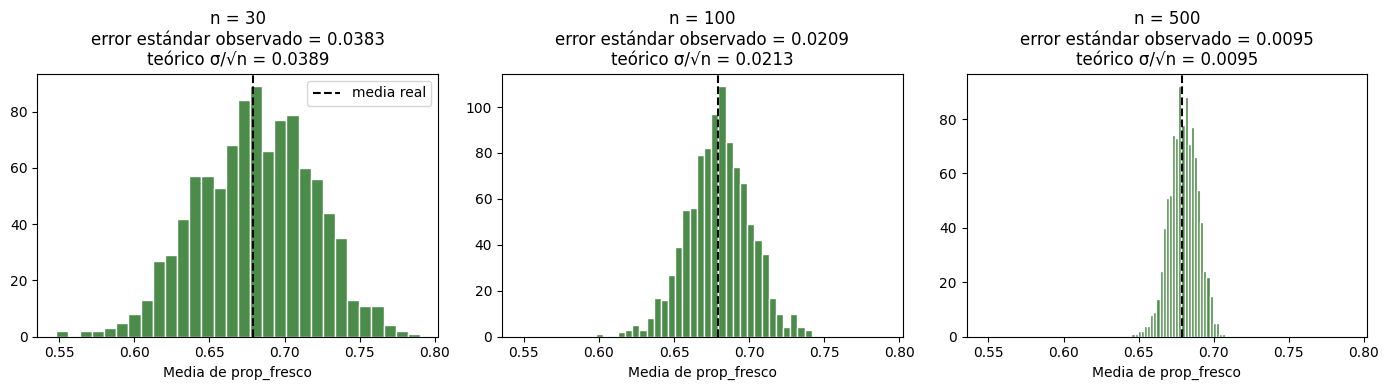

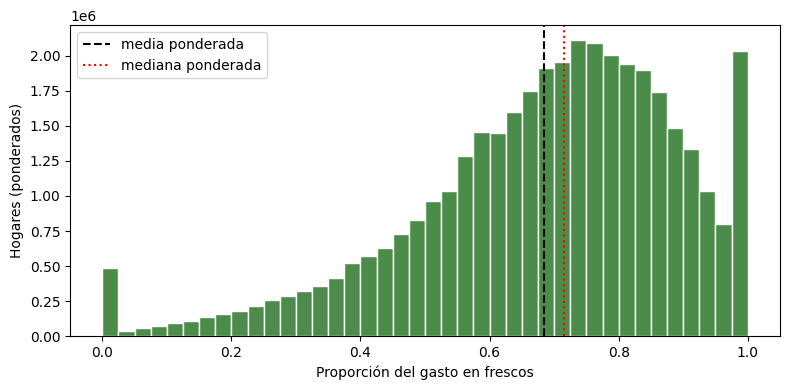

In [8]:
from scipy import stats

x = df['prop_fresco'].values
w = df['factor'].values

# Mediana ponderada: ordenamos los valores y buscamos donde el peso acumulado llega a la mitad
def mediana_pond(valores, pesos):
    orden = np.argsort(valores)
    v, p = valores[orden], pesos[orden]
    acumulado = np.cumsum(p)
    return v[np.searchsorted(acumulado, acumulado[-1] / 2)]

# Estimadores centrales, sin ponderar y ponderados
tabla = {
    'Media (sin ponderar)':        x.mean(),
    'Media (ponderada)':           np.average(x, weights=w),
    'Mediana (sin ponderar)':      np.median(x),
    'Mediana (ponderada)':         mediana_pond(x, w),
    'Media recortada 10%':         stats.trim_mean(x, 0.10),   # descarta 10% de cada extremo
    'Desviación estándar':         x.std(ddof=1),
    'MAD (desv. absoluta mediana)': stats.median_abs_deviation(x),
}
for nombre, valor in tabla.items():
    print(f"{nombre:<30} {valor:.4f}")

# Intervalo de confianza del 95% para la media ponderada, por bootstrap:
# remuestreamos hogares con reemplazo 1,000 veces y recalculamos la media ponderada cada vez
rng = np.random.default_rng(42)
n = len(x)
medias_boot = np.empty(1000)
for i in range(1000):
    idx = rng.integers(0, n, size=n)
    medias_boot[i] = np.average(x[idx], weights=w[idx])
ic = np.percentile(medias_boot, [2.5, 97.5])
print(f"\nIC 95% bootstrap de la media ponderada: [{ic[0]:.4f}, {ic[1]:.4f}]")
print(f"Error estándar (bootstrap): {medias_boot.std():.5f}")

# Distribución muestral de la media: 1,000 muestras SIN reemplazo para cada tamaño n
fig, ejes = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for ax, tam in zip(ejes, [30, 100, 500]):
    medias = [rng.choice(x, size=tam, replace=False).mean() for _ in range(1000)]
    ax.hist(medias, bins=30, color='#4c8c4a', edgecolor='white')
    ax.axvline(x.mean(), color='black', linestyle='--', label='media real')
    ax.set_title(f"n = {tam}\nerror estándar observado = {np.std(medias):.4f}\nteórico σ/√n = {x.std(ddof=1)/np.sqrt(tam):.4f}")
    ax.set_xlabel("Media de prop_fresco")
ejes[0].legend()
plt.tight_layout()
plt.savefig('fig_distribucion_muestral.png', dpi=200)
plt.show()

# Distribución de prop_fresco por hogar, con media y mediana ponderadas
plt.figure(figsize=(8, 4))
plt.hist(x, bins=40, weights=w, color='#4c8c4a', edgecolor='white')
plt.axvline(np.average(x, weights=w), color='black', linestyle='--', label='media ponderada')
plt.axvline(mediana_pond(x, w), color='red', linestyle=':', label='mediana ponderada')
plt.xlabel("Proporción del gasto en frescos"); plt.ylabel("Hogares (ponderados)")
plt.legend(); plt.tight_layout()
plt.savefig('fig_distribucion_prop_fresco.png', dpi=200)
plt.show()

prop = 0 (solo procesados)   hogares:   1310 | % ponderado:   1.2 | mediana gasto_base:     1344 | prom. integrantes: 1.99
prop = 1 (solo frescos)      hogares:   4631 | % ponderado:   4.6 | mediana gasto_base:     3639 | prom. integrantes: 2.74
interiores (0 < prop < 1)    hogares:  84181 | % ponderado:  94.2 | mediana gasto_base:     8948 | prom. integrantes: 3.45

Efecto de quitar outliers sobre prop_fresco
Método      atípicos  media pond.  desv. est.  razón totales pond.
Ninguno            0       0.6848      0.2131               0.6905
z > 3           1195       0.6867      0.2074               0.6905
IQR             2796       0.6883      0.2034               0.6912
LOF 1%           902       0.6856      0.2115               0.6918

KS gasto_base vs lognormal: KstestResult(statistic=np.float64(0.06959553435608756), pvalue=np.float64(1.6744298627064548e-21), statistic_location=np.float64(7301.47), statistic_sign=np.int8(-1))
Beta ajustada: a = 3.49, b = 1.74
KS prop_fresco (inter

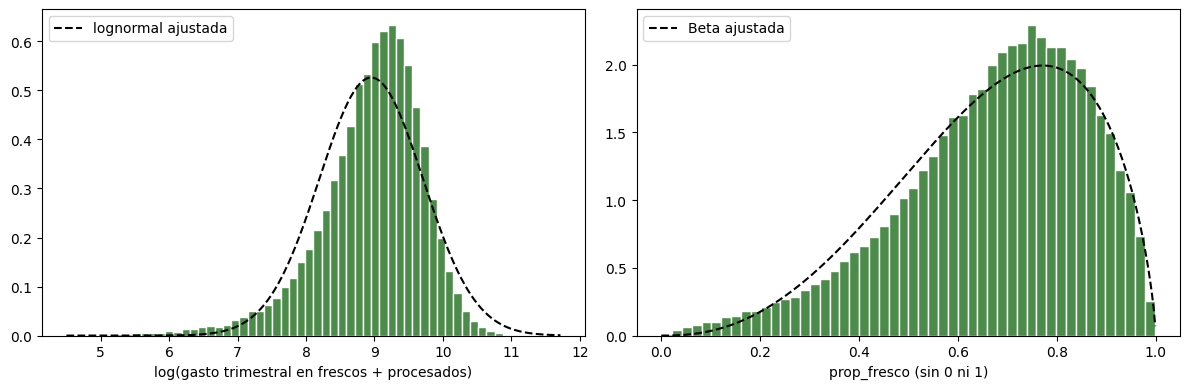

In [9]:
from scipy import stats
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

df['log_gasto_base'] = np.log(df['gasto_base'])   # el gasto es muy asimétrico: trabajamos en logaritmo
x = df['prop_fresco'].values
w = df['factor'].values

# --- A. Hogares en los extremos (proporción exactamente 0 o 1) ---
extremo = (df['prop_fresco'] == 0) | (df['prop_fresco'] == 1)
for nombre, m in [('prop = 0 (solo procesados)', df['prop_fresco'] == 0),
                  ('prop = 1 (solo frescos)',   df['prop_fresco'] == 1),
                  ('interiores (0 < prop < 1)', ~extremo)]:
    sub = df[m]
    print(f"{nombre:<28} hogares: {len(sub):>6} | % ponderado: {100*sub['factor'].sum()/w.sum():5.1f} "
          f"| mediana gasto_base: {sub['gasto_base'].median():8.0f} | prom. integrantes: {sub['tot_integ'].mean():.2f}")

# --- B. Detección de outliers con tres métodos ---
lg = df['log_gasto_base']
mask_z = ((lg - lg.mean()) / lg.std()).abs() > 3                 # z-score > 3
q1, q3 = lg.quantile([0.25, 0.75]); iqr = q3 - q1
mask_iqr = (lg < q1 - 1.5 * iqr) | (lg > q3 + 1.5 * iqr)         # regla del IQR (1.5)

# LOF mira varias variables a la vez: gasto, proporción e ingreso (todas estandarizadas)
X = StandardScaler().fit_transform(np.column_stack([lg, df['prop_fresco'], np.log1p(df['ing_cor'].clip(lower=0))]))
mask_lof = LocalOutlierFactor(n_neighbors=20, contamination=0.01).fit_predict(X) == -1

print("\nEfecto de quitar outliers sobre prop_fresco")
print(f"{'Método':<10} {'atípicos':>9} {'media pond.':>12} {'desv. est.':>11} {'razón totales pond.':>20}")
for nombre, m in [('Ninguno', pd.Series(False, index=df.index)), ('z > 3', mask_z), ('IQR', mask_iqr), ('LOF 1%', pd.Series(mask_lof, index=df.index))]:
    s = df[~m]
    print(f"{nombre:<10} {m.sum():>9} {np.average(s['prop_fresco'], weights=s['factor']):>12.4f} "
          f"{s['prop_fresco'].std():>11.4f} "
          f"{(s['gasto_fresco']*s['factor']).sum()/(s['gasto_base']*s['factor']).sum():>20.4f}")

# --- C. Ajuste de distribuciones ---
# Gasto: lognormal (floc=0 fija el origen en cero); KS sobre una muestra de 5,000 hogares
params_ln = stats.lognorm.fit(df['gasto_base'], floc=0)
muestra = df['gasto_base'].sample(5000, random_state=42)
print("\nKS gasto_base vs lognormal:", stats.kstest(muestra, 'lognorm', args=params_ln))

# Proporción: Beta, solo con los valores interiores (la Beta no admite 0 ni 1 exactos)
interior = df.loc[~extremo, 'prop_fresco']
a, b, loc, scale = stats.beta.fit(interior, floc=0, fscale=1)
print(f"Beta ajustada: a = {a:.2f}, b = {b:.2f}")
print("KS prop_fresco (interior) vs Beta:", stats.kstest(interior.sample(5000, random_state=42), 'beta', args=(a, b, 0, 1)))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(lg, bins=60, density=True, color='#4c8c4a', edgecolor='white')
t = np.linspace(lg.min(), lg.max(), 300)
ejes[0].plot(t, stats.norm.pdf(t, lg.mean(), lg.std()), 'k--', label='lognormal ajustada')
ejes[0].set_xlabel("log(gasto trimestral en frescos + procesados)"); ejes[0].legend()
ejes[1].hist(interior, bins=50, density=True, color='#4c8c4a', edgecolor='white')
t = np.linspace(0.001, 0.999, 300)
ejes[1].plot(t, stats.beta.pdf(t, a, b), 'k--', label='Beta ajustada')
ejes[1].set_xlabel("prop_fresco (sin 0 ni 1)"); ejes[1].legend()
plt.tight_layout(); plt.savefig('fig_ajuste_distribuciones.png', dpi=200); plt.show()

           ing_cor  ing_minmax   ing_z  log_ing_z
mean  7.219318e+04       0.004    0.00      0.000
std   9.374594e+04       0.005    1.00      1.000
min   0.000000e+00       0.000   -0.77    -14.846
max   1.743198e+07       1.000  185.18      7.834
Asimetría (skew) del ingreso: 78.87 | en logaritmo: -0.28

Igual ancho (10 intervalos): hogares por intervalo
[90108    10     2     1     0     0     0     0     0     1]
Deciles: hogares por decil
[9013 9012 9012 9012 9012 9012 9012 9012 9012 9013]

Columnas one-hot: ['loc_1', 'loc_2', 'loc_3', 'loc_4', 'estrato_1', 'estrato_2', 'estrato_3', 'estrato_4']

Tasa de hogares con mayoría de gasto en procesados: 0.18

WOE e IV (IV: <0.02 inútil, 0.02-0.1 débil, 0.1-0.3 medio, >0.3 fuerte)

decil_ing  IV = 0.0268
decil_ing
1     0.193
2     0.183
3     0.119
4     0.113
5     0.072
6     0.015
7    -0.039
8    -0.112
9    -0.101
10   -0.360

est_socio  IV = 0.0472
est_socio
1    0.279
2    0.075
3   -0.209
4   -0.451

tam_loc  IV = 0.0713
tam_lo

/tmp/ipykernel_1234/3149569407.py:43: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  por_decil = df.groupby('decil_ing').apply(lambda g: np.average(g['prop_fresco'], weights=g['factor']))


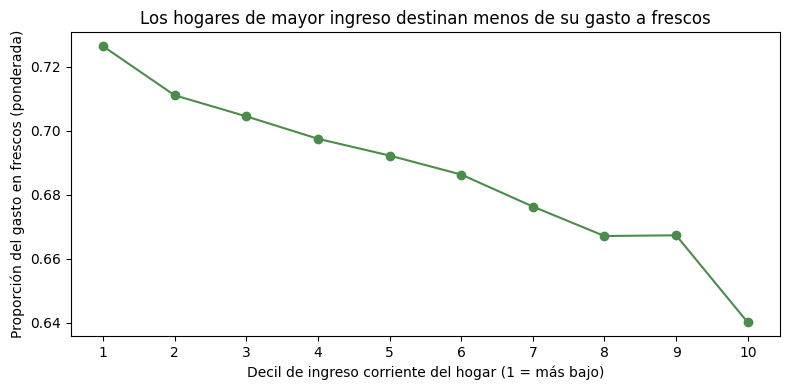

decil_ing
1     0.727
2     0.711
3     0.705
4     0.698
5     0.692
6     0.686
7     0.676
8     0.667
9     0.667
10    0.640
dtype: float64


In [10]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# --- Escalado: ingreso original frente a transformaciones ---
df['ing_minmax'] = MinMaxScaler().fit_transform(df[['ing_cor']])                # lleva todo al rango 0-1
df['ing_z'] = StandardScaler().fit_transform(df[['ing_cor']])                   # media 0 y desviación 1
df['log_ing_z'] = StandardScaler().fit_transform(np.log1p(df[['ing_cor']].clip(lower=0)))  # log + estandarización
print(df[['ing_cor', 'ing_minmax', 'ing_z', 'log_ing_z']].describe().loc[['mean', 'std', 'min', 'max']].round(3))
print("Asimetría (skew) del ingreso:", round(df['ing_cor'].skew(), 2),
      "| en logaritmo:", round(np.log1p(df['ing_cor'].clip(lower=0)).skew(), 2))

# --- Discretización: intervalos de igual ancho vs deciles ---
print("\nIgual ancho (10 intervalos): hogares por intervalo")
print(pd.cut(df['ing_cor'], 10).value_counts().sort_index().values)
df['decil_ing'] = pd.qcut(df['ing_cor'], 10, labels=False, duplicates='drop') + 1
print("Deciles: hogares por decil")
print(df['decil_ing'].value_counts().sort_index().values)

# --- One-hot de variables categóricas ---
onehot = pd.get_dummies(df[['tam_loc', 'est_socio']].astype(str), prefix=['loc', 'estrato'])
print("\nColumnas one-hot:", list(onehot.columns))

# --- Evento binario para WOE y para los modelos ---
df['mayoria_procesados'] = (df['prop_fresco'] < 0.5).astype(int)
print("\nTasa de hogares con mayoría de gasto en procesados:", round(df['mayoria_procesados'].mean(), 3))

# --- WOE (weight of evidence) e IV (information value) ---
def woe_iv(datos, variable, evento='mayoria_procesados'):
    t = datos.groupby(variable)[evento].agg(['sum', 'count'])
    malos = t['sum']                      # hogares con evento (mayoría procesados)
    buenos = t['count'] - t['sum']        # hogares sin evento
    pct_m, pct_b = malos / malos.sum(), buenos / buenos.sum()
    woe = np.log(pct_b / pct_m)           # WOE = ln(% sin evento / % con evento)
    iv = ((pct_b - pct_m) * woe).sum()    # IV total de la variable
    return woe.round(3), round(iv, 4)

print("\nWOE e IV (IV: <0.02 inútil, 0.02-0.1 débil, 0.1-0.3 medio, >0.3 fuerte)")
for var in ['decil_ing', 'est_socio', 'tam_loc']:
    woe, iv = woe_iv(df, var)
    print(f"\n{var}  IV = {iv}")
    print(woe.to_string())

# --- Gráfica principal de H3: % de frescos por decil de ingreso (ponderado) ---
por_decil = df.groupby('decil_ing').apply(lambda g: np.average(g['prop_fresco'], weights=g['factor']))
plt.figure(figsize=(8, 4))
plt.plot(por_decil.index, por_decil.values, marker='o', color='#4c8c4a')
plt.xticks(range(1, 11))
plt.xlabel("Decil de ingreso corriente del hogar (1 = más bajo)")
plt.ylabel("Proporción del gasto en frescos (ponderada)")
plt.title("Los hogares de mayor ingreso destinan menos de su gasto a frescos")
plt.tight_layout(); plt.savefig('fig_prop_fresco_por_decil.png', dpi=200); plt.show()
print(por_decil.round(3))

In [11]:
from scipy import stats

rng = np.random.default_rng(42)

# --- Funciones auxiliares de tamaño de efecto ---
def cohen_d(a, b):
    """Diferencia de medias en unidades de desviación estándar combinada."""
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
    return (a.mean() - b.mean()) / sp

def cliffs_delta(a, b):
    """Probabilidad de que un hogar de A supere a uno de B, menos la contraria (-1 a 1)."""
    u = stats.mannwhitneyu(a, b).statistic
    return 2 * u / (len(a) * len(b)) - 1

def ic_dif_pond(da, db, reps=500):
    """IC 95% bootstrap de la diferencia de medias ponderadas de prop_fresco (A - B)."""
    difs = []
    for _ in range(reps):
        sa = da.sample(len(da), replace=True, random_state=int(rng.integers(1e9)))
        sb = db.sample(len(db), replace=True, random_state=int(rng.integers(1e9)))
        difs.append(np.average(sa['prop_fresco'], weights=sa['factor']) - np.average(sb['prop_fresco'], weights=sb['factor']))
    return np.percentile(difs, [2.5, 97.5])

def comparar(da, db, nombre):
    """Reporta todas las pruebas y tamaños de efecto para dos grupos."""
    a, b = da['prop_fresco'].values, db['prop_fresco'].values
    dif = np.average(a, weights=da['factor']) - np.average(b, weights=db['factor'])
    lo, hi = ic_dif_pond(da, db)
    print(f"\n{nombre}  (n = {len(a)} vs {len(b)})")
    print(f"  Diferencia de medias ponderadas: {dif:+.4f}  IC95% [{lo:+.4f}, {hi:+.4f}]")
    print(f"  Welch t-test p = {stats.ttest_ind(a, b, equal_var=False).pvalue:.2e}")
    print(f"  Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.2e}")
    print(f"  Prueba de la mediana p = {stats.median_test(a, b)[1]:.2e}")
    print(f"  Cohen d = {cohen_d(a, b):+.3f} | Cliff delta = {cliffs_delta(a, b):+.3f}")

# --- H1: estrato socioeconómico (Kruskal-Wallis entre 4 grupos) ---
def kruskal_con_efecto(datos, variable):
    grupos = [g['prop_fresco'].values for _, g in datos.groupby(variable)]
    H, p = stats.kruskal(*grupos)
    n, k = len(datos), len(grupos)
    eps2 = (H - k + 1) / (n - k)   # tamaño de efecto: 0.01 pequeño, 0.06 mediano, 0.14 grande
    print(f"Kruskal-Wallis {variable}: H = {H:.1f}, p = {p:.2e}, epsilon² = {eps2:.4f}")

print("=== H1: estrato ===")
kruskal_con_efecto(df, 'est_socio')
comparar(df[df['est_socio'] == 1], df[df['est_socio'] == 4], "Estrato 1 (bajo) vs Estrato 4 (alto)")

# --- H2: tamaño de localidad ---
print("\n=== H2: tamaño de localidad ===")
kruskal_con_efecto(df, 'tam_loc')
comparar(df[df['tam_loc'] == 4], df[df['tam_loc'] == 1], "Rural (<2,500) vs Urbano grande (>=100,000)")

# --- H3: ingreso (Spearman + IC bootstrap) ---
print("\n=== H3: ingreso ===")
rho, p = stats.spearmanr(df['ing_cor'], df['prop_fresco'])
rhos = []
for _ in range(200):
    s = df.sample(len(df), replace=True, random_state=int(rng.integers(1e9)))
    rhos.append(stats.spearmanr(s['ing_cor'], s['prop_fresco'])[0])
print(f"Spearman rho = {rho:.3f}, p = {p:.2e}, IC95% bootstrap [{np.percentile(rhos, 2.5):.3f}, {np.percentile(rhos, 97.5):.3f}]")

# --- Comparación tipo A/B: jefatura del hogar ---
print("\n=== Jefatura del hogar (sexo_jefe) ===")
print(df['sexo_jefe'].value_counts())            # verifica que existan los códigos 1 y 2
hombre, mujer = df[df['sexo_jefe'] == 1], df[df['sexo_jefe'] == 2]
comparar(mujer, hombre, "Jefatura mujer (2) vs hombre (1)")

# ¿La diferencia persiste dentro de cada estrato? (revisa confusión con nivel socioeconómico)
print("\nDiferencia mujer - hombre dentro de cada estrato (media ponderada):")
for e in [1, 2, 3, 4]:
    m, h = mujer[mujer['est_socio'] == e], hombre[hombre['est_socio'] == e]
    d = np.average(m['prop_fresco'], weights=m['factor']) - np.average(h['prop_fresco'], weights=h['factor'])
    print(f"  Estrato {e}: {d:+.4f}")

# --- Sensibilidad: repetir lo principal sin los hogares extremos (prop = 0 o 1) ---
print("\n=== Sensibilidad: sin hogares con prop_fresco = 0 o 1 ===")
sin_ext = df[(df['prop_fresco'] > 0) & (df['prop_fresco'] < 1)]
comparar(sin_ext[sin_ext['est_socio'] == 1], sin_ext[sin_ext['est_socio'] == 4], "Estrato 1 vs 4")
comparar(sin_ext[sin_ext['tam_loc'] == 4], sin_ext[sin_ext['tam_loc'] == 1], "Rural vs urbano grande")

=== H1: estrato ===
Kruskal-Wallis est_socio: H = 881.1, p = 1.09e-190, epsilon² = 0.0097

Estrato 1 (bajo) vs Estrato 4 (alto)  (n = 18633 vs 8011)
  Diferencia de medias ponderadas: +0.0932  IC95% [+0.0855, +0.1010]
  Welch t-test p = 1.35e-123
  Mann-Whitney p = 7.25e-127
  Prueba de la mediana p = 1.67e-95
  Cohen d = +0.337 | Cliff delta = +0.185

=== H2: tamaño de localidad ===
Kruskal-Wallis tam_loc: H = 1439.6, p = 0.00e+00, epsilon² = 0.0159

Rural (<2,500) vs Urbano grande (>=100,000)  (n = 35234 vs 33815)
  Diferencia de medias ponderadas: +0.0682  IC95% [+0.0642, +0.0719]
  Welch t-test p = 1.05e-237
  Mann-Whitney p = 8.14e-239
  Prueba de la mediana p = 1.38e-166
  Cohen d = +0.252 | Cliff delta = +0.145

=== H3: ingreso ===
Spearman rho = -0.102, p = 3.08e-206, IC95% bootstrap [-0.110, -0.095]

=== Jefatura del hogar (sexo_jefe) ===
sexo_jefe
1    61004
2    29118
Name: count, dtype: int64

Jefatura mujer (2) vs hombre (1)  (n = 29118 vs 61004)
  Diferencia de medias pon

In [12]:
import statsmodels.formula.api as smf

df['log_ing'] = np.log1p(df['ing_cor'].clip(lower=0))   # ingreso en logaritmo (por su asimetría)

# Regresión ponderada con el factor de expansión y errores estándar robustos (HC1)
# Categorías de referencia: estrato 1, localidad 1 (urbana grande), jefatura hombre (1)
modelo = smf.wls('prop_fresco ~ log_ing + C(est_socio) + C(tam_loc) + tot_integ + C(sexo_jefe)',
                 data=df, weights=df['factor']).fit(cov_type='HC1')
print(modelo.summary().tables[1])
print("R² =", round(modelo.rsquared, 4))

                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.9247      0.018     50.677      0.000       0.889       0.961
C(est_socio)[T.2]    -0.0105      0.003     -4.135      0.000      -0.016      -0.006
C(est_socio)[T.3]    -0.0157      0.004     -4.440      0.000      -0.023      -0.009
C(est_socio)[T.4]    -0.0225      0.005     -4.922      0.000      -0.032      -0.014
C(tam_loc)[T.2]       0.0222      0.003      7.037      0.000       0.016       0.028
C(tam_loc)[T.3]       0.0334      0.004      9.445      0.000       0.026       0.040
C(tam_loc)[T.4]       0.0368      0.003     14.153      0.000       0.032       0.042
C(sexo_jefe)[T.2]     0.0242      0.002     11.506      0.000       0.020       0.028
log_ing              -0.0272      0.002    -15.556      0.000      -0.031      -0.024
tot_integ             0.0137      0.001     21.297    

Variables de entrada: 15 ['g_0111', 'g_0112', 'g_0113', 'g_0114', 'g_0115', 'g_0116', 'g_0117', 'g_0118', 'g_0119', 'g_0121', 'g_0122', 'g_0123', 'g_0124', 'g_0126', 'g_0129']

Varianza explicada por componente: [0.104 0.088 0.081 0.076 0.072]
Componentes necesarios para 80% de la varianza: 11

Cargas (ordenadas por peso en PC1):
         PC1   PC2
g_0111  0.50 -0.19
g_0117 -0.45 -0.27
g_0126  0.45  0.31
g_0112 -0.37  0.57
g_0116 -0.35 -0.16
g_0121  0.15 -0.01
g_0113 -0.12  0.13
g_0115 -0.12 -0.24
g_0114  0.11 -0.43
g_0129  0.08  0.07
g_0119  0.06  0.22
g_0123 -0.06 -0.00
g_0118 -0.04 -0.31
g_0122  0.01 -0.20
g_0124  0.01  0.03


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


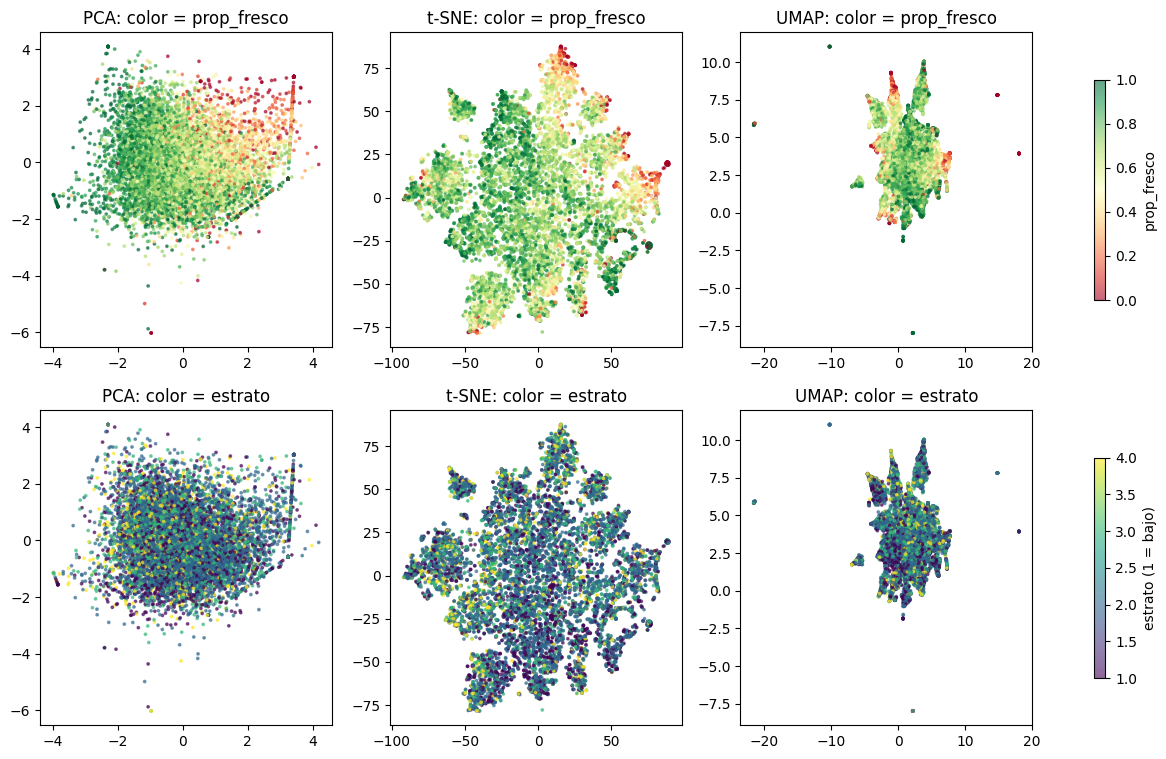


Silueta (sobre las proyecciones 2D):
  PCA    por est_socio: -0.015
  PCA    por tam_loc  : -0.036
  t-SNE  por est_socio: -0.025
  t-SNE  por tam_loc  : -0.030
  UMAP   por est_socio: -0.038
  UMAP   por tam_loc  : -0.031


In [13]:
!pip install umap-learn --quiet
import umap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

# Participación del gasto en cada grupo de alimento (cada fila suma 1)
cols_g = [c for c in df.columns if c.startswith('g_')]
comp = df[cols_g].div(df[cols_g].sum(axis=1), axis=0)
X = StandardScaler().fit_transform(comp)       # estandarizamos para que ningún grupo domine
print("Variables de entrada:", len(cols_g), cols_g)

# --- PCA con todos los componentes: varianza explicada ---
pca = PCA().fit(X)
var_exp = pca.explained_variance_ratio_
acum = np.cumsum(var_exp)
print("\nVarianza explicada por componente:", var_exp[:5].round(3))
print("Componentes necesarios para 80% de la varianza:", int(np.argmax(acum >= 0.80)) + 1)

# Qué grupos pesan más en PC1 y PC2
cargas = pd.DataFrame(pca.components_[:2].T, index=cols_g, columns=['PC1', 'PC2']).round(2)
print("\nCargas (ordenadas por peso en PC1):")
print(cargas.reindex(cargas['PC1'].abs().sort_values(ascending=False).index))

# --- Muestra de 10,000 hogares para t-SNE y UMAP ---
muestra = df.sample(10000, random_state=42)
pos = df.index.get_indexer(muestra.index)
Xs = X[pos]
emb = {
    'PCA':   pca.transform(Xs)[:, :2],
    't-SNE': TSNE(n_components=2, perplexity=30, init='pca', random_state=42).fit_transform(Xs),
    'UMAP':  umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42).fit_transform(Xs),
}

# --- Gráficas: arriba coloreado por prop_fresco, abajo por estrato ---
fig, ejes = plt.subplots(2, 3, figsize=(16, 9))
for j, (nombre, e) in enumerate(emb.items()):
    sc = ejes[0, j].scatter(e[:, 0], e[:, 1], c=muestra['prop_fresco'], cmap='RdYlGn', s=3, alpha=0.6)
    ejes[0, j].set_title(f"{nombre}: color = prop_fresco")
    sc2 = ejes[1, j].scatter(e[:, 0], e[:, 1], c=muestra['est_socio'], cmap='viridis', s=3, alpha=0.6)
    ejes[1, j].set_title(f"{nombre}: color = estrato")
fig.colorbar(sc, ax=ejes[0, :], shrink=0.7, label='prop_fresco')
fig.colorbar(sc2, ax=ejes[1, :], shrink=0.7, label='estrato (1 = bajo)')
plt.savefig('fig_reduccion_dimensionalidad.png', dpi=200, bbox_inches='tight'); plt.show()

# --- Coeficiente de silueta: ¿los grupos socioeconómicos se separan en 2D? ---
# Cerca de 0 = grupos mezclados; cerca de 1 = grupos bien separados
print("\nSilueta (sobre las proyecciones 2D):")
for nombre, e in emb.items():
    for etiqueta in ['est_socio', 'tam_loc']:
        s = silhouette_score(e, muestra[etiqueta], sample_size=5000, random_state=42)
        print(f"  {nombre:<6} por {etiqueta:<9}: {s:+.3f}")

Tamaños train/val/test: 54073 18024 18025
Tasa de la clase minoritaria: 0.18 0.18 0.18

Validación (referencia: ROC-AUC = 0.5 y PR-AUC = prevalencia = 0.18 )
                                    ROC-AUC  PR-AUC  recall  precisión     F1
modelo                                                                       
Gradient Boosting | Pesos de clase    0.690   0.330   0.613      0.282  0.386
Gradient Boosting | Sin balanceo      0.690   0.330   0.031      0.550  0.058
Gradient Boosting | SMOTE             0.685   0.325   0.511      0.306  0.383
Gradient Boosting | Submuestreo       0.687   0.321   0.624      0.279  0.386
Logística | Sin balanceo              0.668   0.296   0.005      0.469  0.009
Logística | Pesos de clase            0.668   0.294   0.618      0.263  0.369
Logística | Submuestreo               0.666   0.294   0.623      0.262  0.369
Logística | SMOTE                     0.663   0.292   0.571      0.269  0.365


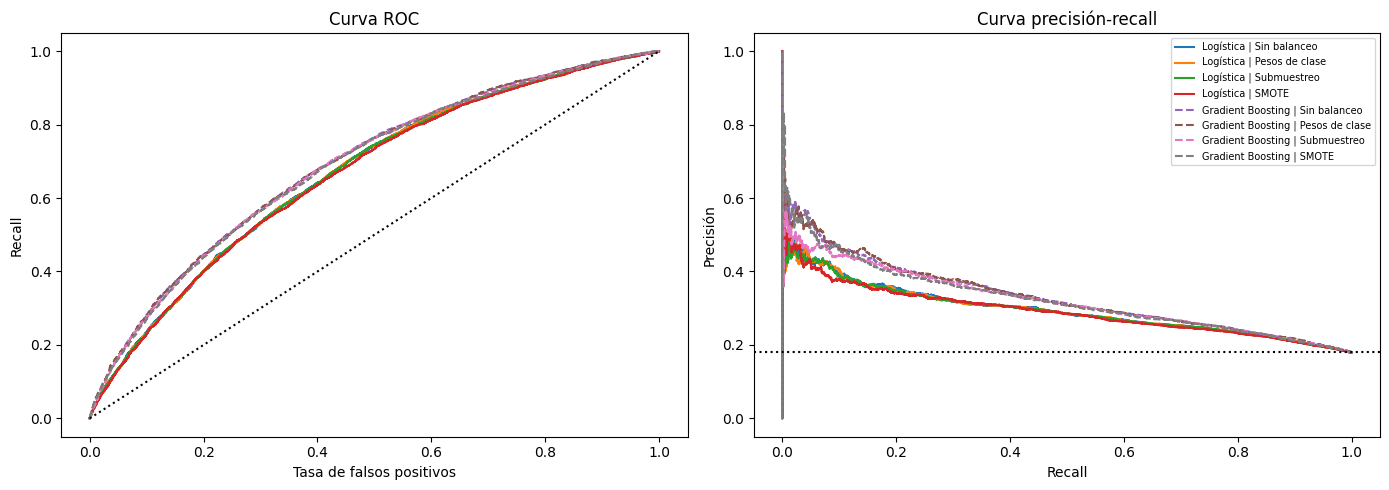

In [14]:
!pip install imbalanced-learn --quiet
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             recall_score, precision_score, roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# --- Variables de entrada (solo socioeconómicas y territoriales) ---
datos = df.copy()
datos['log_ing'] = np.log1p(datos['ing_cor'].clip(lower=0))
datos['jefa_mujer'] = (datos['sexo_jefe'] == 2).astype(int)
X_cat = pd.get_dummies(datos[['est_socio', 'tam_loc', 'entidad']].astype(str), prefix=['est', 'loc', 'ent'], dtype=int)
X = pd.concat([datos[['log_ing', 'tot_integ', 'jefa_mujer']], X_cat], axis=1)
y = datos['mayoria_procesados']

# --- Partición 60-20-20 estratificada (mantiene el 18% en cada parte) ---
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.40, stratify=y, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)
print("Tamaños train/val/test:", len(X_tr), len(X_val), len(X_te))
print("Tasa de la clase minoritaria:", round(y_tr.mean(), 3), round(y_val.mean(), 3), round(y_te.mean(), 3))

# --- Estandarizar las numéricas (se ajusta SOLO con entrenamiento) ---
cols_esc = ['log_ing', 'tot_integ']
esc = StandardScaler().fit(X_tr[cols_esc])
def escalar(m):
    m = m.copy(); m[cols_esc] = esc.transform(m[cols_esc]); return m
X_tr_s, X_val_s, X_te_s = escalar(X_tr), escalar(X_val), escalar(X_te)

# --- Estrategias de balanceo (solo se aplican al entrenamiento) ---
Xu, yu = RandomUnderSampler(random_state=42).fit_resample(X_tr_s, y_tr)
Xs, ys = SMOTE(random_state=42).fit_resample(X_tr_s, y_tr)
estrategias = {
    'Sin balanceo':   (X_tr_s, y_tr, None),
    'Pesos de clase': (X_tr_s, y_tr, 'balanced'),
    'Submuestreo':    (Xu, yu, None),
    'SMOTE':          (Xs, ys, None),
}

def crear(modelo, cw):
    if modelo == 'Logística':
        return LogisticRegression(max_iter=1000, class_weight=cw)
    return HistGradientBoostingClassifier(max_depth=4, max_iter=200, learning_rate=0.1, class_weight=cw, random_state=42)

# --- Entrenar los 8 modelos y evaluar en VALIDACIÓN ---
filas, ajustados, probs_val = [], {}, {}
for modelo in ['Logística', 'Gradient Boosting']:
    for est, (Xe, ye, cw) in estrategias.items():
        m = crear(modelo, cw).fit(Xe, ye)
        p = m.predict_proba(X_val_s)[:, 1]
        pred = (p >= 0.5).astype(int)
        clave = f"{modelo} | {est}"
        ajustados[clave], probs_val[clave] = m, p
        filas.append({'modelo': clave, 'ROC-AUC': roc_auc_score(y_val, p), 'PR-AUC': average_precision_score(y_val, p),
                      'recall': recall_score(y_val, pred), 'precisión': precision_score(y_val, pred, zero_division=0),
                      'F1': f1_score(y_val, pred)})
resultados = pd.DataFrame(filas).set_index('modelo').round(3).sort_values('PR-AUC', ascending=False)
print("\nValidación (referencia: ROC-AUC = 0.5 y PR-AUC = prevalencia =", round(y_val.mean(), 3), ")")
print(resultados)

# --- Curvas ROC y precisión-recall de los 8 modelos ---
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for clave, p in probs_val.items():
    estilo = '-' if clave.startswith('Log') else '--'
    fpr, tpr, _ = roc_curve(y_val, p); ejes[0].plot(fpr, tpr, estilo, label=clave)
    pr, rc, _ = precision_recall_curve(y_val, p); ejes[1].plot(rc, pr, estilo, label=clave)
ejes[0].plot([0, 1], [0, 1], 'k:'); ejes[0].set_xlabel('Tasa de falsos positivos'); ejes[0].set_ylabel('Recall'); ejes[0].set_title('Curva ROC')
ejes[1].axhline(y_val.mean(), color='k', linestyle=':'); ejes[1].set_xlabel('Recall'); ejes[1].set_ylabel('Precisión'); ejes[1].set_title('Curva precisión-recall')
ejes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig('fig_curvas_roc_pr.png', dpi=200); plt.show()

Mejor modelo en validación: Gradient Boosting | Pesos de clase

Evaluación FINAL en prueba
ROC-AUC = 0.699 | PR-AUC = 0.335 (referencia PR-AUC = 0.180)
  Sin calibrar  Brier = 0.2165 | ECE = 0.2750
  Platt         Brier = 0.1360 | ECE = 0.0098
  Isotónica     Brier = 0.1361 | ECE = 0.0093

Umbral (máx. F1 en validación) = 0.520 -> prueba: precisión = 0.298, recall = 0.588, F1 = 0.395


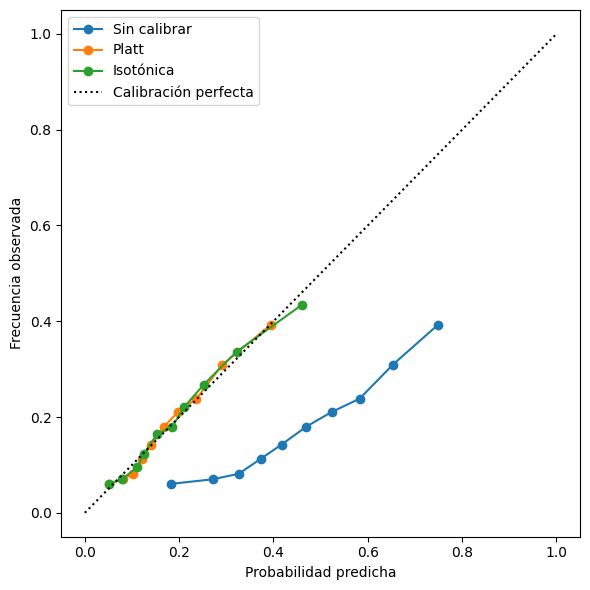

In [15]:
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

mejor = resultados.index[0]                      # el de mayor PR-AUC en validación
modelo = ajustados[mejor]
p_val = probs_val[mejor]
p_te = modelo.predict_proba(X_te_s)[:, 1]
print("Mejor modelo en validación:", mejor)

# Calibración: Platt (sigmoide sobre el logit) e isotónica, ajustadas con validación
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p)).reshape(-1, 1)
platt = LogisticRegression().fit(logit(p_val), y_val)
iso = IsotonicRegression(out_of_bounds='clip').fit(p_val, y_val)
versiones = {'Sin calibrar': p_te,
             'Platt': platt.predict_proba(logit(p_te))[:, 1],
             'Isotónica': iso.predict(p_te)}

def ece(y_real, p, bins=10):
    """Error de calibración esperado: diferencia promedio entre probabilidad y frecuencia real."""
    cortes = np.quantile(p, np.linspace(0, 1, bins + 1)); cortes[-1] += 1e-9
    total = 0
    for i in range(bins):
        m = (p >= cortes[i]) & (p < cortes[i + 1])
        if m.sum(): total += m.sum() * abs(y_real[m].mean() - p[m].mean())
    return total / len(p)

print("\nEvaluación FINAL en prueba")
print(f"ROC-AUC = {roc_auc_score(y_te, p_te):.3f} | PR-AUC = {average_precision_score(y_te, p_te):.3f} "
      f"(referencia PR-AUC = {y_te.mean():.3f})")
for nombre, p in versiones.items():
    print(f"  {nombre:<13} Brier = {brier_score_loss(y_te, p):.4f} | ECE = {ece(y_te.values, p):.4f}")

# Umbral que maximiza F1 en validación, aplicado a prueba
pr, rc, th = precision_recall_curve(y_val, p_val)
f1s = 2 * pr * rc / (pr + rc + 1e-12)
umbral = th[np.argmax(f1s[:-1])]
pred = (p_te >= umbral).astype(int)
print(f"\nUmbral (máx. F1 en validación) = {umbral:.3f} -> prueba: precisión = {precision_score(y_te, pred):.3f}, "
      f"recall = {recall_score(y_te, pred):.3f}, F1 = {f1_score(y_te, pred):.3f}")

# Curva de confiabilidad (reliability diagram)
plt.figure(figsize=(6, 6))
for nombre, p in versiones.items():
    obs, esp = calibration_curve(y_te, p, n_bins=10, strategy='quantile')
    plt.plot(esp, obs, marker='o', label=nombre)
plt.plot([0, 1], [0, 1], 'k:', label='Calibración perfecta')
plt.xlabel('Probabilidad predicha'); plt.ylabel('Frecuencia observada'); plt.legend()
plt.tight_layout(); plt.savefig('fig_calibracion.png', dpi=200); plt.show()

Épocas entrenadas por el MLP: 30

                               ROC-AUC  PR-AUC
Perceptrón (lineal)             0.571   0.226
Logística (sin balanceo)        0.668   0.296
MLP (32-16)                     0.692   0.331
Gradient Boosting (sin bal.)    0.690   0.330


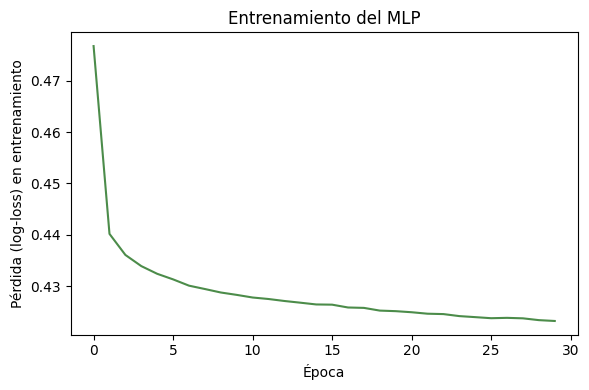

In [16]:
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier

# Perceptrón: modelo lineal; no da probabilidades, usamos su puntaje (decision_function) para el AUC
percep = Perceptron(max_iter=1000, tol=1e-3, class_weight='balanced', random_state=42).fit(X_tr_s, y_tr)
s_per = percep.decision_function(X_val_s)

# MLP: dos capas ocultas (32 y 16 neuronas), con parada temprana para evitar sobreajuste
mlp = MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', early_stopping=True,
                    validation_fraction=0.1, n_iter_no_change=10, max_iter=300, random_state=42).fit(X_tr_s, y_tr)
p_mlp = mlp.predict_proba(X_val_s)[:, 1]
print("Épocas entrenadas por el MLP:", mlp.n_iter_)

# Comparación con los modelos anteriores (validación)
comparacion = pd.DataFrame({
    'Perceptrón (lineal)':         [roc_auc_score(y_val, s_per), average_precision_score(y_val, s_per)],
    'Logística (sin balanceo)':    [resultados.loc['Logística | Sin balanceo', 'ROC-AUC'], resultados.loc['Logística | Sin balanceo', 'PR-AUC']],
    'MLP (32-16)':                 [roc_auc_score(y_val, p_mlp), average_precision_score(y_val, p_mlp)],
    'Gradient Boosting (sin bal.)': [resultados.loc['Gradient Boosting | Sin balanceo', 'ROC-AUC'], resultados.loc['Gradient Boosting | Sin balanceo', 'PR-AUC']],
}, index=['ROC-AUC', 'PR-AUC']).T.round(3)
print("\n", comparacion)

# Curva de pérdida del MLP durante el entrenamiento
plt.figure(figsize=(6, 4))
plt.plot(mlp.loss_curve_, color='#4c8c4a')
plt.xlabel("Época"); plt.ylabel("Pérdida (log-loss) en entrenamiento")
plt.title("Entrenamiento del MLP")
plt.tight_layout(); plt.savefig('fig_curva_perdida_mlp.png', dpi=200); plt.show()

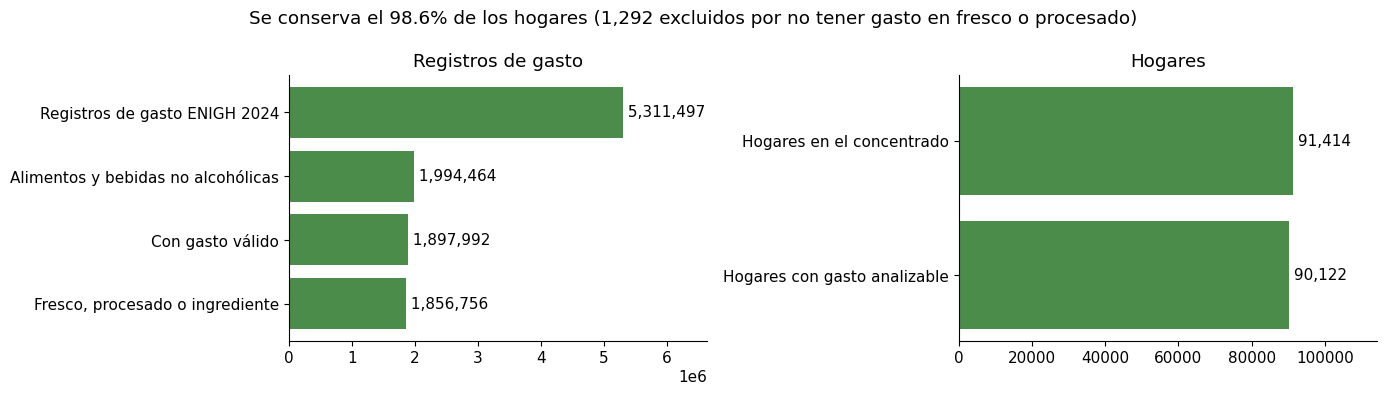

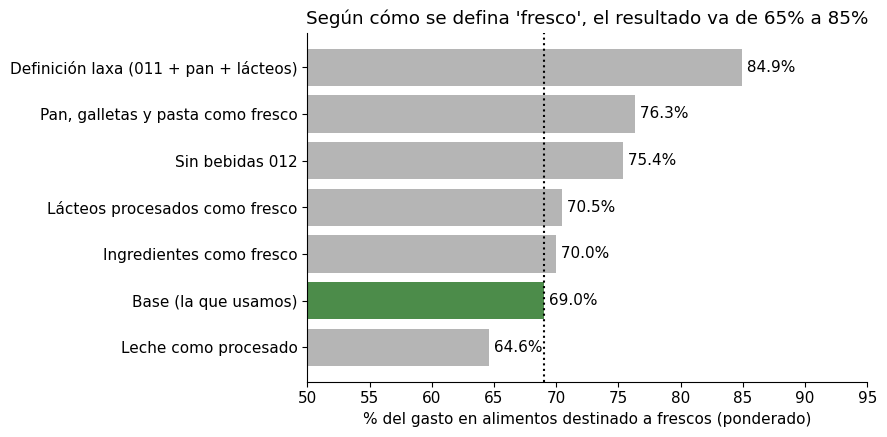

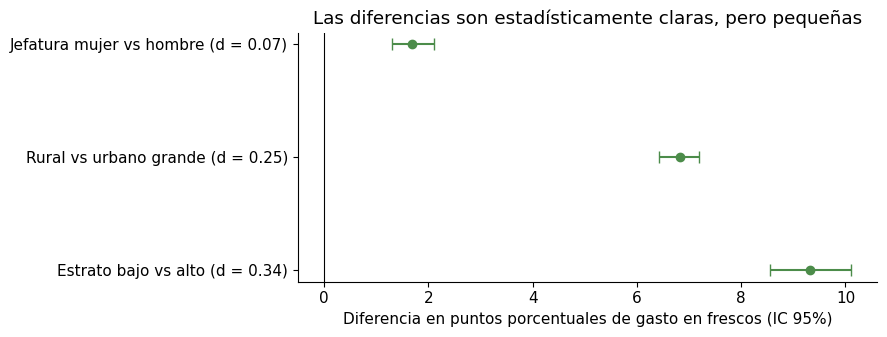

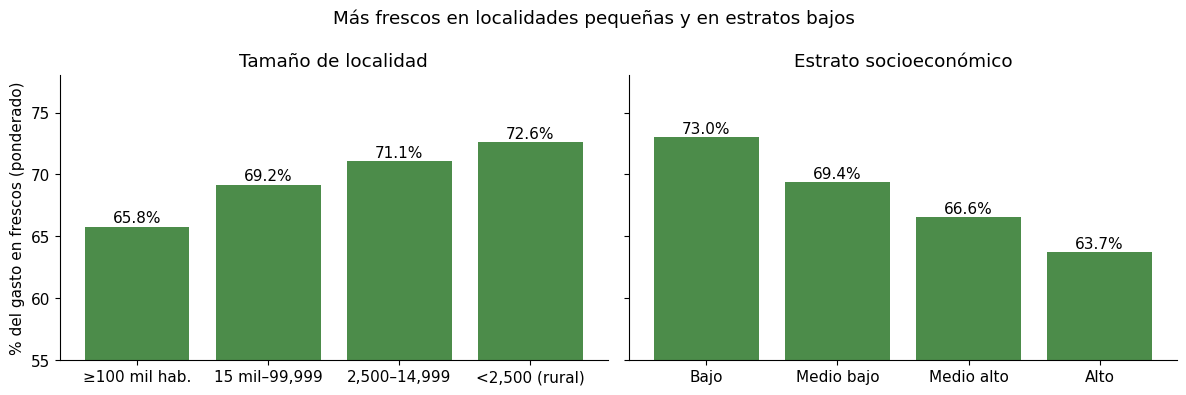

Hogares sin nombre de entidad: 0


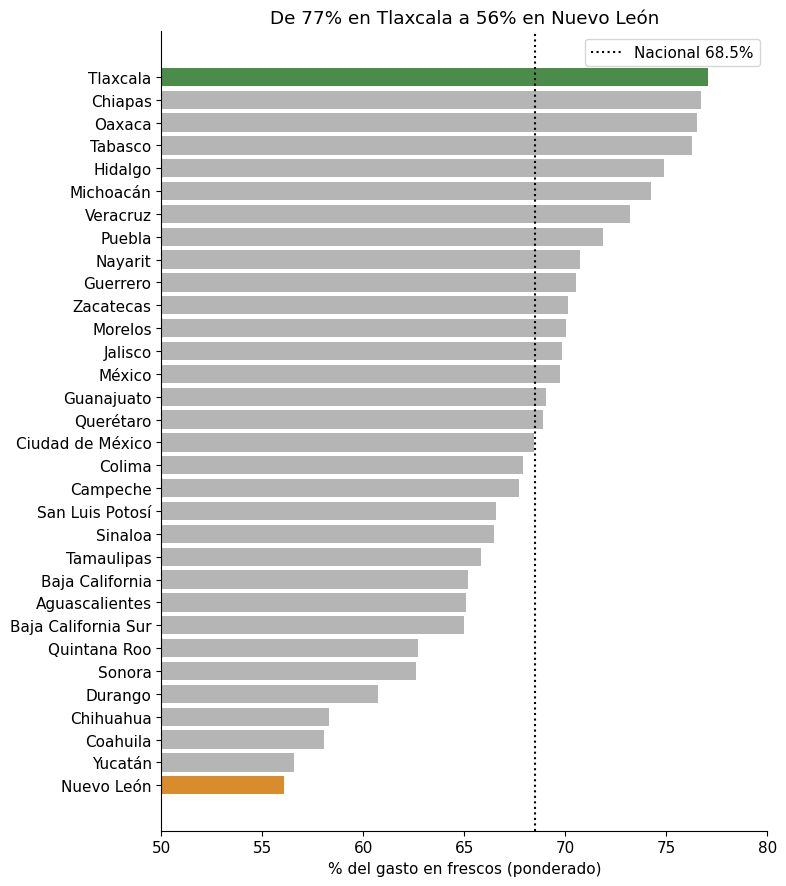

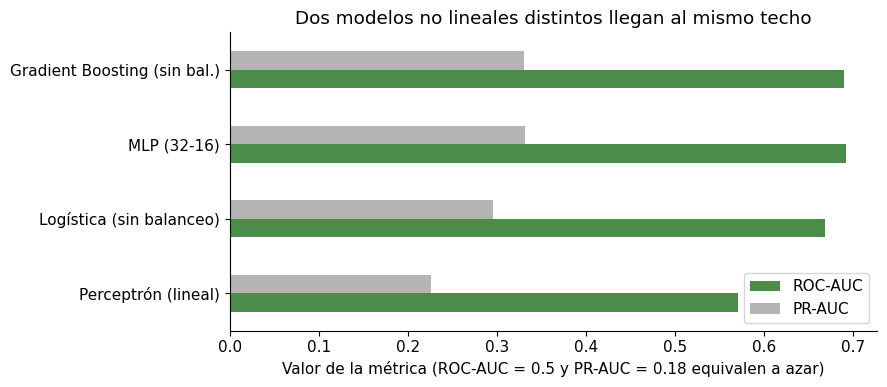

hogares_analizados            90122.0000
hogares_excluidos              1292.0000
prop_fresco_media_pond            0.6848
prop_fresco_mediana_pond          0.7159
prop_fresco_media_sin_pond        0.6792
razon_totales_pond                0.6905
tasa_mayoria_procesados           0.1797
test_roc_auc                      0.6989
test_pr_auc                       0.3354
test_brier_sin_calibrar           0.2165
test_brier_platt                  0.1360
test_ece_sin_calibrar             0.2750
test_ece_platt                    0.0098
sens_Base (la que usamos)         0.6905
dtype: float64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
assert 'pct_fresco' in globals(), "Primero corre el Paso 3 en esta sesión (define las funciones de sensibilidad)."

VERDE, GRIS, NARANJA = '#4c8c4a', '#b5b5b5', '#d98c2b'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 11})

def pmed(variable):
    """Proporción de frescos media ponderada por nivel de una variable."""
    return (df['prop_fresco'] * df['factor']).groupby(df[variable]).sum() / df['factor'].groupby(df[variable]).sum()

def mediana_pond(v, p):
    o = np.argsort(v); v, p = np.asarray(v)[o], np.asarray(p)[o]; c = np.cumsum(p)
    return v[np.searchsorted(c, c[-1] / 2)]

media_nac = np.average(df['prop_fresco'], weights=df['factor'])

# ---------- F1: embudo de filtrado (registros y hogares) ----------
alim = df_gastos[df_gastos['categoria'] != 'Otro']
reg = [('Registros de gasto ENIGH 2024', len(df_gastos)),
       ('Alimentos y bebidas no alcohólicas', len(alim)),
       ('Con gasto válido', int(alim['gasto_tri'].notna().sum())),
       ('Fresco, procesado o ingrediente', len(gastos_analisis))]
hog = [('Hogares en el concentrado', len(df_concentrado)), ('Hogares con gasto analizable', len(df))]
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for ax, etapas, titulo in [(ejes[0], reg, 'Registros de gasto'), (ejes[1], hog, 'Hogares')]:
    nombres, vals = zip(*etapas)
    ax.barh(nombres[::-1], vals[::-1], color=VERDE)
    for i, v in enumerate(vals[::-1]): ax.text(v, i, f" {v:,}", va='center')
    ax.set_title(titulo); ax.set_xlim(0, max(vals) * 1.25)
fig.suptitle(f"Se conserva el {100*len(df)/len(df_concentrado):.1f}% de los hogares ({len(df_concentrado)-len(df):,} excluidos por no tener gasto en fresco o procesado)")
plt.tight_layout(); plt.savefig('fig_embudo.png', dpi=200); plt.show()

# ---------- F2: sensibilidad de la definición de "fresco" ----------
sens = {
    'Base (la que usamos)':                       pct_fresco(mapa_categoria),
    'Sin bebidas 012':                            pct_fresco(mapa_categoria, solo_011=True),
    'Pan, galletas y pasta como fresco':          pct_fresco(variante({c: 'Fresco' for c in pan_pasta})),
    'Lácteos procesados como fresco':             pct_fresco(variante({c: 'Fresco' for c in lacteos_proc})),
    'Leche como procesado':                       pct_fresco(variante({'011411': 'Procesado'})),
    'Ingredientes como fresco':                   pct_fresco(mapa_categoria, ingredientes_como_fresco=True),
    'Definición laxa (011 + pan + lácteos)':      pct_fresco(variante({c: 'Fresco' for c in pan_pasta + lacteos_proc}), solo_011=True),
}
s = pd.Series(sens).sort_values()
plt.figure(figsize=(9, 4.5))
plt.barh(s.index, s.values * 100, color=[VERDE if i.startswith('Base') else GRIS for i in s.index])
for i, v in enumerate(s.values): plt.text(v * 100, i, f" {v:.1%}", va='center')
plt.axvline(sens['Base (la que usamos)'] * 100, color='black', linestyle=':')
plt.xlim(50, 95); plt.xlabel("% del gasto en alimentos destinado a frescos (ponderado)")
plt.title(f"Según cómo se defina 'fresco', el resultado va de {s.min():.0%} a {s.max():.0%}")
plt.tight_layout(); plt.savefig('fig_sensibilidad.png', dpi=200); plt.show()

# ---------- F3: diferencias entre grupos con IC 95% (valores del Paso 7) ----------
ef = pd.DataFrame({'comparación': ['Estrato bajo vs alto (d = 0.34)', 'Rural vs urbano grande (d = 0.25)', 'Jefatura mujer vs hombre (d = 0.07)'],
                   'dif': [9.32, 6.82, 1.69], 'lo': [8.55, 6.42, 1.31], 'hi': [10.10, 7.19, 2.10]})
plt.figure(figsize=(9, 3.5))
plt.errorbar(ef['dif'], range(3), xerr=[ef['dif'] - ef['lo'], ef['hi'] - ef['dif']], fmt='o', color=VERDE, capsize=4)
plt.yticks(range(3), ef['comparación']); plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("Diferencia en puntos porcentuales de gasto en frescos (IC 95%)")
plt.title("Las diferencias son estadísticamente claras, pero pequeñas")
plt.tight_layout(); plt.savefig('fig_efectos.png', dpi=200); plt.show()

# ---------- F4: frescos por tamaño de localidad y por estrato ----------
loc = pmed('tam_loc').rename({1: '≥100 mil hab.', 2: '15 mil–99,999', 3: '2,500–14,999', 4: '<2,500 (rural)'})
est = pmed('est_socio').rename({1: 'Bajo', 2: 'Medio bajo', 3: 'Medio alto', 4: 'Alto'})
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, serie, tit in [(ejes[0], loc, 'Tamaño de localidad'), (ejes[1], est, 'Estrato socioeconómico')]:
    ax.bar(serie.index, serie.values * 100, color=VERDE)
    for i, v in enumerate(serie.values): ax.text(i, v * 100 + 0.3, f"{v:.1%}", ha='center')
    ax.set_title(tit); ax.set_ylim(55, 78)
ejes[0].set_ylabel("% del gasto en frescos (ponderado)")
fig.suptitle("Más frescos en localidades pequeñas y en estratos bajos")
plt.tight_layout(); plt.savefig('fig_localidad_estrato.png', dpi=200); plt.show()

# ---------- F5: ranking por entidad federativa ----------
nombres_ent = {1:'Aguascalientes',2:'Baja California',3:'Baja California Sur',4:'Campeche',5:'Coahuila',6:'Colima',7:'Chiapas',
               8:'Chihuahua',9:'Ciudad de México',10:'Durango',11:'Guanajuato',12:'Guerrero',13:'Hidalgo',14:'Jalisco',15:'México',
               16:'Michoacán',17:'Morelos',18:'Nayarit',19:'Nuevo León',20:'Oaxaca',21:'Puebla',22:'Querétaro',23:'Quintana Roo',
               24:'San Luis Potosí',25:'Sinaloa',26:'Sonora',27:'Tabasco',28:'Tamaulipas',29:'Tlaxcala',30:'Veracruz',31:'Yucatán',32:'Zacatecas'}
df['entidad_nom'] = pd.to_numeric(df['entidad'], errors='coerce').map(nombres_ent)
print("Hogares sin nombre de entidad:", int(df['entidad_nom'].isna().sum()))
ent = pmed('entidad_nom').sort_values()
plt.figure(figsize=(8, 9))
colores = [NARANJA if i == 0 else VERDE if i == len(ent) - 1 else GRIS for i in range(len(ent))]
plt.barh(ent.index, ent.values * 100, color=colores)
plt.axvline(media_nac * 100, color='black', linestyle=':', label=f"Nacional {media_nac:.1%}")
plt.xlim(50, 80); plt.xlabel("% del gasto en frescos (ponderado)"); plt.legend()
plt.title(f"De {ent.iloc[-1]:.0%} en {ent.index[-1]} a {ent.iloc[0]:.0%} en {ent.index[0]}")
plt.tight_layout(); plt.savefig('fig_entidades.png', dpi=200); plt.show()

# ---------- F6: escalera de modelos (validación) ----------
comparacion.plot.barh(figsize=(9, 4), color=[VERDE, GRIS])
plt.xlabel("Valor de la métrica (ROC-AUC = 0.5 y PR-AUC = 0.18 equivalen a azar)")
plt.title("Dos modelos no lineales distintos llegan al mismo techo")
plt.tight_layout(); plt.savefig('fig_modelos.png', dpi=200); plt.show()

# ---------- Cifras clave en un solo archivo ----------
cifras = {
    'hogares_analizados': len(df), 'hogares_excluidos': len(df_concentrado) - len(df),
    'prop_fresco_media_pond': media_nac,
    'prop_fresco_mediana_pond': mediana_pond(df['prop_fresco'].values, df['factor'].values),
    'prop_fresco_media_sin_pond': df['prop_fresco'].mean(),
    'razon_totales_pond': (df['gasto_fresco'] * df['factor']).sum() / (df['gasto_base'] * df['factor']).sum(),
    'tasa_mayoria_procesados': df['mayoria_procesados'].mean(),
    'test_roc_auc': roc_auc_score(y_te, p_te), 'test_pr_auc': average_precision_score(y_te, p_te),
    'test_brier_sin_calibrar': brier_score_loss(y_te, versiones['Sin calibrar']),
    'test_brier_platt': brier_score_loss(y_te, versiones['Platt']),
    'test_ece_sin_calibrar': ece(y_te.values, versiones['Sin calibrar']),
    'test_ece_platt': ece(y_te.values, versiones['Platt']),
}
for k, v in sens.items(): cifras['sens_' + k] = v
for k, v in loc.items(): cifras['loc_' + k] = v
for k, v in est.items(): cifras['estrato_' + k] = v
for k, v in ent.items(): cifras['entidad_' + k] = v
pd.Series(cifras, name='valor').round(4).to_csv('cifras_clave.csv')
print(pd.Series(cifras).round(4).head(14))

# Descarga de todo en un solo zip
!zip -q figuras_proyecto.zip fig_*.png cifras_clave.csv
from google.colab import files
files.download('figuras_proyecto.zip')

In [18]:
# Guarda los datos de las figuras para rehacerlas con el estilo del reporte y la presentación.
# No modifica nada del análisis.
from sklearn.metrics import roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve

assert isinstance(muestra, pd.DataFrame), "Vuelve a correr el Paso 8: 'muestra' debe ser la muestra de 10,000 hogares."

rng = np.random.default_rng(42)
x = df['prop_fresco'].values
extremo = (df['prop_fresco'] == 0) | (df['prop_fresco'] == 1)

paquete = {
    'prop_fresco': x.astype('float32'),
    'factor': df['factor'].values.astype('float32'),
    'log_gasto_base': np.log(df['gasto_base'].values).astype('float32'),
    'prop_interior': df.loc[~extremo, 'prop_fresco'].values.astype('float32'),
    'decil_prop_fresco': por_decil.values,
    'pca_var_exp': pca.explained_variance_ratio_,
    'mlp_loss': np.array(mlp.loss_curve_),
    'prevalencia': np.array([y_val.mean()]),
}

# Distribución muestral de la media (tres tamaños de muestra)
for n in [30, 100, 500]:
    paquete[f'medias_n{n}'] = np.array([rng.choice(x, size=n, replace=False).mean() for _ in range(1000)])

# Proyecciones 2D (PCA, t-SNE, UMAP) y las etiquetas de cada punto
for nombre, e in emb.items():
    paquete['emb_' + nombre] = e.astype('float32')
paquete['emb_prop_fresco'] = muestra['prop_fresco'].values.astype('float32')
paquete['emb_estrato'] = muestra['est_socio'].values
paquete['emb_localidad'] = muestra['tam_loc'].values

# Curvas ROC y precisión-recall de los 8 modelos (validación)
paquete['modelos'] = np.array(list(probs_val.keys()))
for i, p in enumerate(probs_val.values()):
    fpr, tpr, _ = roc_curve(y_val, p)
    pr, rc, _ = precision_recall_curve(y_val, p)
    paquete[f'roc_fpr_{i}'], paquete[f'roc_tpr_{i}'] = fpr.astype('float32'), tpr.astype('float32')
    paquete[f'pr_prec_{i}'], paquete[f'pr_rec_{i}'] = pr.astype('float32'), rc.astype('float32')

# Curva de calibración (prueba): sin calibrar, Platt e isotónica
paquete['cal_nombres'] = np.array(list(versiones.keys()))
for i, p in enumerate(versiones.values()):
    obs, esp = calibration_curve(y_te, p, n_bins=10, strategy='quantile')
    paquete[f'cal_obs_{i}'], paquete[f'cal_esp_{i}'] = obs, esp

np.savez_compressed('datos_figuras.npz', **paquete)
import os
print("Tamaño del archivo:", round(os.path.getsize('datos_figuras.npz') / 1e6, 1), "MB")
from google.colab import files
files.download('datos_figuras.npz')

Tamaño del archivo: 1.8 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# ===== Celda única: información para los anexos B y C =====
import pandas as pd

# --- Anexo B: claves por categoría ---
print("=== ANEXO B: CLAVES POR CATEGORÍA ===")
tabla_claves = (gastos_analisis.groupby(['categoria', 'clave'])['gasto_tri']
                .agg(['count', 'sum']).reset_index())    # nº de registros y gasto total por clave
tabla_claves.columns = ['categoria', 'clave', 'registros', 'gasto_tri_total']
print(tabla_claves.sort_values(['categoria', 'gasto_tri_total'],
                               ascending=[True, False]).to_string(index=False))

# --- Anexo C1: proporción de frescos por entidad (ponderada) ---
print("\n=== ANEXO C1: ENTIDADES (media ponderada) ===")
def media_pond(d):
    return (d['prop_fresco'] * d['factor']).sum() / d['factor'].sum()   # media con factor de expansión
ent = (df.groupby('entidad_nom').apply(media_pond)
         .sort_values(ascending=False).round(4))
print(ent.to_string())

# --- Anexo C2: proporción de frescos por decil de ingreso (ponderada) ---
print("\n=== ANEXO C2: DECILES DE INGRESO (media ponderada) ===")
dec = (df.groupby('decil_ing').apply(media_pond).round(4))
print(dec.to_string())

=== ANEXO B: CLAVES POR CATEGORÍA ===
  categoria  clave  registros  gasto_tri_total
     Fresco 011131     267843      87367314.76
     Fresco 011481      89936      52719242.62
     Fresco 011411      79373      39882729.09
     Fresco 011221      20910      38912486.62
     Fresco 01122F      19437      29152901.36
     Fresco 011727      84966      26602937.63
     Fresco 011224      15318      21513025.20
     Fresco 011761      33025      18239310.96
     Fresco 011451      26799      16475532.02
     Fresco 011751      40557      15250142.70
     Fresco 011743      52802      12741099.57
     Fresco 011133      36148      11441578.33
     Fresco 011228       7062      10641036.66
     Fresco 011633      20755      10143229.04
     Fresco 011111      29191       9273986.42
     Fresco 011611      17611       8868402.43
     Fresco 011454      12850       8582984.76
     Fresco 01122C       6054       8359689.05
     Fresco 011310       4167       7514161.60
     Fresco 011229    

/tmp/ipykernel_1234/4033957450.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  ent = (df.groupby('entidad_nom').apply(media_pond)
/tmp/ipykernel_1234/4033957450.py:22: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  dec = (df.groupby('decil_ing').apply(media_pond).round(4))


In [20]:
# ===== Diagnóstico: qué tablas (DataFrames) existen en esta sesión =====
import pandas as pd

for nombre, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and not nombre.startswith('_'):
        print(f"{nombre}: {obj.shape[0]:,} filas x {obj.shape[1]} columnas")
        print("   columnas:", list(obj.columns)[:40])   # primeras 40 columnas

df_gastos: 5,311,497 filas x 34 columnas
   columnas: ['folioviv', 'foliohog', 'clave', 'tipo_gasto', 'mes_dia', 'forma_pag1', 'forma_pag2', 'forma_pag3', 'lugar_comp', 'orga_inst', 'frecuencia', 'fecha_adqu', 'fecha_pago', 'cantidad', 'gasto', 'pago_mp', 'costo', 'inmujer', 'inst_1', 'inst_2', 'num_meses', 'num_pagos', 'ultim_pago', 'gasto_tri', 'gasto_nm', 'gas_nm_tri', 'imujer_tri', 'entidad', 'est_dis', 'upm', 'factor', 'grupo3', 'categoria', 'grupo4']
df_concentrado: 91,414 filas x 126 columnas
   columnas: ['folioviv', 'foliohog', 'ubica_geo', 'tam_loc', 'est_socio', 'est_dis', 'upm', 'factor', 'clase_hog', 'sexo_jefe', 'edad_jefe', 'educa_jefe', 'tot_integ', 'hombres', 'mujeres', 'mayores', 'menores', 'p12_64', 'p65mas', 'ocupados', 'percep_ing', 'perc_ocupa', 'ing_cor', 'ingtrab', 'trabajo', 'sueldos', 'horas_extr', 'comisiones', 'aguinaldo', 'indemtrab', 'otra_rem', 'remu_espec', 'negocio', 'noagrop', 'industria', 'comercio', 'servicios', 'agrope', 'agricolas', 'pecuarios']
re

In [24]:
# Guarda la tabla final de hogares (una fila por hogar) como CSV
columnas = ['folioviv', 'foliohog', 'gasto_fresco', 'gasto_ingrediente',
            'gasto_procesado', 'prop_fresco', 'ing_cor', 'tam_loc',
            'est_socio', 'factor', 'sexo_jefe', 'tot_integ',
            'entidad_nom', 'decil_ing']
df[columnas].to_csv('hogares_procesados.csv', index=False)   # crea el archivo

from google.colab import files
files.download('hogares_procesados.csv')                     # lo baja a tu computadora

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>